# 70/30 MSCI World / Emerging Markets backtest

The main strategy starts at 70% URTH (MSCI World) and 30% EEM (MSCI Emerging Markets), then rebalances to those target weights once per calendar year. A no-rebalancing version is included as a secondary comparison. ACWI is the broad, market-cap-weighted global equity benchmark; a separate 70/30 benchmark with the same funds and rebalance rule would duplicate the strategy.

Adjusted closing prices are used as a proxy for total returns. The backtest uses USD-listed ETFs, omits trading costs, taxes, and cash flows, and covers January 2015 through October 2026. The primary Sharpe ratio uses a date-matched 3-month U.S. Treasury yield from FRED; a zero-risk-free-rate Sharpe ratio is also shown as a sensitivity check.

The regional analysis compares the 70/30 target with ACWI and MSCI World using a dated iShares holdings snapshot. It puts their emerging-market weights alongside IMF GDP and World Bank market-cap shares.

## Google Colab setup

Run the next code cell once to install `yfinance`. The notebook downloads ETF prices, Treasury yields, IMF GDP, World Bank market-cap data, and iShares holdings over the internet; it does not require the project CSV, Excel, or Python analysis files.


In [ ]:
%pip install -q yfinance


In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True



In [2]:
START_DATE = "2015-01-01"
# yfinance treats `end` as exclusive; this includes data through 2026-10-31.
END_DATE = "2026-11-01"

WORLD_TICKER = "URTH"
EM_TICKER = "EEM"
BENCHMARK_TICKER = "ACWI"
FRED_RISK_FREE_SERIES = "DGS3MO"
TRADING_DAYS_PER_YEAR = 252
ROLLING_WINDOW = 252

STRATEGY_TICKERS = [WORLD_TICKER, EM_TICKER]
ALL_TICKERS = STRATEGY_TICKERS + [BENCHMARK_TICKER]
TARGET_WEIGHTS = pd.Series(
    {WORLD_TICKER: 0.70, EM_TICKER: 0.30},
    dtype=float,
)



In [3]:
raw = yf.download(
    ALL_TICKERS,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
    threads=False,
)

if raw.empty:
    raise RuntimeError("Yahoo Finance returned no price data for the selected tickers and dates.")

if isinstance(raw.columns, pd.MultiIndex):
    close_level = next(
        (
            level
            for level in range(raw.columns.nlevels)
            if "Close" in raw.columns.get_level_values(level)
        ),
        None,
    )
    if close_level is None:
        raise KeyError("The downloaded data has no Close price column.")
    prices = raw.xs("Close", axis=1, level=close_level)
else:
    if "Close" not in raw.columns:
        raise KeyError("The downloaded data has no Close price column.")
    prices = raw[["Close"]].rename(columns={"Close": ALL_TICKERS[0]})

missing_tickers = sorted(set(ALL_TICKERS) - set(prices.columns))
if missing_tickers:
    raise KeyError(f"Price data is missing ticker(s): {', '.join(missing_tickers)}")

# Keep only dates with prices for every ETF so comparisons use identical dates.
prices = prices.reindex(columns=ALL_TICKERS).dropna(how="any")
if len(prices) < 2:
    raise RuntimeError("At least two common price dates are required for the backtest.")

print(f"Using {prices.index[0].date()} to {prices.index[-1].date()} ({len(prices)} trading days).")
print(prices.head())



Using 2015-01-02 to 2026-10-30 (2975 trading days).
Ticker           URTH        EEM       ACWI
Date                                       
2015-01-02  57.947815  30.198093  46.700165
2015-01-05  56.589108  29.660646  45.779926
2015-01-06  55.836956  29.536018  45.307789
2015-01-07  56.403095  30.174711  45.899956
2015-01-08  57.656681  30.688795  46.620136


In [4]:
# FRED reports DGS3MO as an annualized percent yield. Convert the previous
# trading day's yield into an approximate return over each price interval.
fred_url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    f"?id={FRED_RISK_FREE_SERIES}&cosd={START_DATE}&coed={END_DATE}"
)
risk_free_data = pd.read_csv(fred_url, index_col=0, parse_dates=True)
if FRED_RISK_FREE_SERIES not in risk_free_data.columns:
    raise KeyError(f"FRED data is missing series {FRED_RISK_FREE_SERIES}.")

risk_free_yield = pd.to_numeric(
    risk_free_data[FRED_RISK_FREE_SERIES],
    errors="coerce",
).dropna()
if risk_free_yield.empty:
    raise RuntimeError("FRED returned no observations for the risk-free rate series.")

risk_free_yield = risk_free_yield.sort_index().reindex(prices.index).ffill()
if risk_free_yield.isna().any():
    raise RuntimeError("FRED risk-free rate data does not cover the backtest start date.")

calendar_days = prices.index.to_series().diff().dt.days
daily_risk_free_returns = (
    (1 + risk_free_yield.shift(1) / 100)
    ** (calendar_days / 365.25)
    - 1
).dropna()
daily_risk_free_returns.name = "3-month Treasury risk-free return"



In [5]:
def simulate_portfolio(
    asset_returns: pd.DataFrame,
    target_weights: pd.Series,
    rebalance_annually: bool,
) -> tuple[pd.Series, pd.DataFrame]:
    """Simulate daily portfolio returns and closing weights from daily asset returns."""
    weights = target_weights.astype(float).copy()
    portfolio_returns = []
    closing_weights = []

    for position, (date, daily_asset_returns) in enumerate(asset_returns.iterrows()):
        day_returns = daily_asset_returns[target_weights.index]
        portfolio_return = float((weights * day_returns).sum())
        end_values = weights * (1 + day_returns)
        weights = end_values / (1 + portfolio_return)

        if (
            rebalance_annually
            and position + 1 < len(asset_returns)
            and asset_returns.index[position + 1].year != date.year
        ):
            # Rebalance at this calendar-year close for the next year's returns.
            weights = target_weights.astype(float).copy()

        portfolio_returns.append(portfolio_return)
        closing_weights.append(weights.copy())

    returns = pd.Series(
        portfolio_returns,
        index=asset_returns.index,
        name="Portfolio return",
    )
    weights_over_time = pd.DataFrame(closing_weights, index=asset_returns.index)
    weights_over_time.columns = target_weights.index
    return returns, weights_over_time


def equity_curve_from_returns(returns: pd.Series, initial_date: pd.Timestamp) -> pd.Series:
    """Create a growth-of-one series with an initial value on the first price date."""
    growth = (1 + returns).cumprod()
    initial_value = pd.Series([1.0], index=pd.DatetimeIndex([initial_date]))
    return pd.concat([initial_value, growth]).rename(returns.name)


asset_returns = prices[STRATEGY_TICKERS].pct_change().dropna()
strategy_returns, strategy_weights = simulate_portfolio(
    asset_returns,
    TARGET_WEIGHTS,
    rebalance_annually=True,
)
buy_and_hold_returns, buy_and_hold_weights = simulate_portfolio(
    asset_returns,
    TARGET_WEIGHTS,
    rebalance_annually=False,
)

strategy_value = equity_curve_from_returns(strategy_returns, prices.index[0]).rename(
    "70/30 Annual Rebalance"
)
buy_and_hold_value = equity_curve_from_returns(
    buy_and_hold_returns,
    prices.index[0],
).rename("70/30 Buy-and-Hold")
benchmark_returns = prices[BENCHMARK_TICKER].pct_change().dropna()
benchmark_value = equity_curve_from_returns(
    benchmark_returns,
    prices.index[0],
).rename("MSCI ACWI (ACWI)")

equity_curves = pd.concat(
    [strategy_value, buy_and_hold_value, benchmark_value],
    axis="columns",
    sort=False,
)

# Include target weights at inception in the displayed weight histories.
initial_weights_row = pd.DataFrame(
    [TARGET_WEIGHTS],
    index=pd.DatetimeIndex([prices.index[0]]),
)
strategy_weights = pd.concat([initial_weights_row, strategy_weights])
buy_and_hold_weights = pd.concat([initial_weights_row, buy_and_hold_weights])



In [16]:
# %%
def market_model_metrics(
    portfolio_returns: pd.Series,
    benchmark_returns: pd.Series,
    risk_free_returns: pd.Series,
) -> tuple[float, float, pd.Series, pd.Series]:
    """Return annualized CAPM alpha, beta, and aligned daily excess returns."""
    aligned_returns = pd.concat(
        [
            portfolio_returns.rename("portfolio"),
            benchmark_returns.rename("benchmark"),
            risk_free_returns.rename("risk_free"),
        ],
        axis="columns",
        sort=False,
    ).dropna()
    if len(aligned_returns) < 2:
        raise ValueError("At least two aligned return observations are required for alpha and beta.")

    portfolio_excess_returns = aligned_returns["portfolio"] - aligned_returns["risk_free"]
    benchmark_excess_returns = aligned_returns["benchmark"] - aligned_returns["risk_free"]
    benchmark_variance = benchmark_excess_returns.var(ddof=1)
    if not np.isfinite(benchmark_variance) or benchmark_variance <= 0:
        raise ValueError("Benchmark excess returns must have positive variance to calculate beta.")

    beta = float(portfolio_excess_returns.cov(benchmark_excess_returns) / benchmark_variance)
    daily_alpha = float(
        portfolio_excess_returns.mean() - beta * benchmark_excess_returns.mean()
    )
    annualized_alpha = daily_alpha * TRADING_DAYS_PER_YEAR
    return (
        annualized_alpha,
        beta,
        portfolio_excess_returns,
        benchmark_excess_returns,
    )


def performance_metrics(equity_curve: pd.Series, benchmark: pd.Series | None = None) -> pd.Series:
    returns = equity_curve.pct_change().dropna()
    years = (equity_curve.index[-1] - equity_curve.index[0]).days / 365.25
    daily_volatility = returns.std(ddof=1)

    if years <= 0:
        raise ValueError("The backtest needs prices covering more than one calendar day.")

    returns_with_risk_free = pd.concat(
        [
            returns.rename("portfolio"),
            daily_risk_free_returns.reindex(returns.index).rename("risk_free"),
        ],
        axis="columns",
        sort=False,
    ).dropna()
    excess_returns = returns_with_risk_free["portfolio"] - returns_with_risk_free["risk_free"]
    sharpe_ratio = (
        excess_returns.mean() / daily_volatility * np.sqrt(TRADING_DAYS_PER_YEAR)
        if daily_volatility > 0 and not excess_returns.empty
        else np.nan
    )
    zero_risk_free_sharpe = (
        returns.mean() / daily_volatility * np.sqrt(TRADING_DAYS_PER_YEAR)
        if daily_volatility > 0
        else np.nan
    )
    metrics = {
        "Cumulative return": equity_curve.iloc[-1] / equity_curve.iloc[0] - 1,
        "CAGR": (equity_curve.iloc[-1] / equity_curve.iloc[0]) ** (1 / years) - 1,
        "Annualized average return (arithmetic)": returns.mean() * TRADING_DAYS_PER_YEAR,
        "Annualized volatility": daily_volatility * np.sqrt(TRADING_DAYS_PER_YEAR),
        "Sharpe ratio (3-month Treasury)": sharpe_ratio,
        "Sharpe ratio (0% risk-free sensitivity)": zero_risk_free_sharpe,
        "Maximum drawdown": (equity_curve / equity_curve.cummax() - 1).min(),
    }

    if benchmark is not None:
        aligned_returns = pd.concat(
            [returns.rename("strategy"), benchmark.pct_change().rename("benchmark")],
            axis="columns",
            sort=False,
        ).dropna()
        active_returns = aligned_returns["strategy"] - aligned_returns["benchmark"]
        tracking_error = active_returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)
        metrics["Annualized active return"] = active_returns.mean() * TRADING_DAYS_PER_YEAR
        metrics["Tracking error"] = tracking_error
        metrics["Information ratio"] = (
            active_returns.mean() / active_returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)
            if active_returns.std(ddof=1) > 0
            else np.nan
        )
        annualized_alpha, beta, _, _ = market_model_metrics(
            returns,
            benchmark.pct_change().dropna(),
            daily_risk_free_returns,
        )
        metrics["Alpha (annualized, vs. ACWI)"] = annualized_alpha
        metrics["Beta (vs. ACWI)"] = beta

    return pd.Series(metrics)


metrics = pd.DataFrame(
    {
        "70/30 Annual Rebalance": performance_metrics(strategy_value, benchmark_value),
        "70/30 Buy-and-Hold": performance_metrics(buy_and_hold_value, benchmark_value),
        "MSCI ACWI (ACWI)": performance_metrics(benchmark_value),
    }
)

percentage_metrics = [
    "Cumulative return",
    "CAGR",
    "Annualized average return (arithmetic)",
    "Annualized volatility",
    "Maximum drawdown",
    "Annualized active return",
    "Tracking error",
    "Alpha (annualized, vs. ACWI)",
]
formatted_metrics = metrics.astype(object)
for metric in percentage_metrics:
    if metric in metrics.index:
        formatted_metrics.loc[metric] = metrics.loc[metric].map(
            lambda value: f"{value:.2%}" if pd.notna(value) else "N/A"
        )
for metric in [
    "Sharpe ratio (3-month Treasury)",
    "Sharpe ratio (0% risk-free sensitivity)",
    "Information ratio",
    "Beta (vs. ACWI)",
]:
    if metric in metrics.index:
        formatted_metrics.loc[metric] = metrics.loc[metric].map(
            lambda value: f"{value:.2f}" if pd.notna(value) else "N/A"
        )

print("Performance metrics (primary Sharpe uses the daily 3-month Treasury yield):")
print(formatted_metrics.to_string())


Performance metrics (primary Sharpe uses the daily 3-month Treasury yield):
                                        70/30 Annual Rebalance 70/30 Buy-and-Hold MSCI ACWI (ACWI)
Alpha (annualized, vs. ACWI)                            -0.86%             -0.73%              N/A
Annualized active return                                -0.73%             -0.62%              N/A
Annualized average return (arithmetic)                  10.92%             11.03%           11.65%
Annualized volatility                                   17.38%             17.28%           16.87%
Beta (vs. ACWI)                                           1.01               1.01              N/A
CAGR                                                     9.84%              9.98%           10.74%
Cumulative return                                      203.25%            207.84%          234.13%
Information ratio                                        -0.23              -0.23              N/A
Maximum drawdown                 

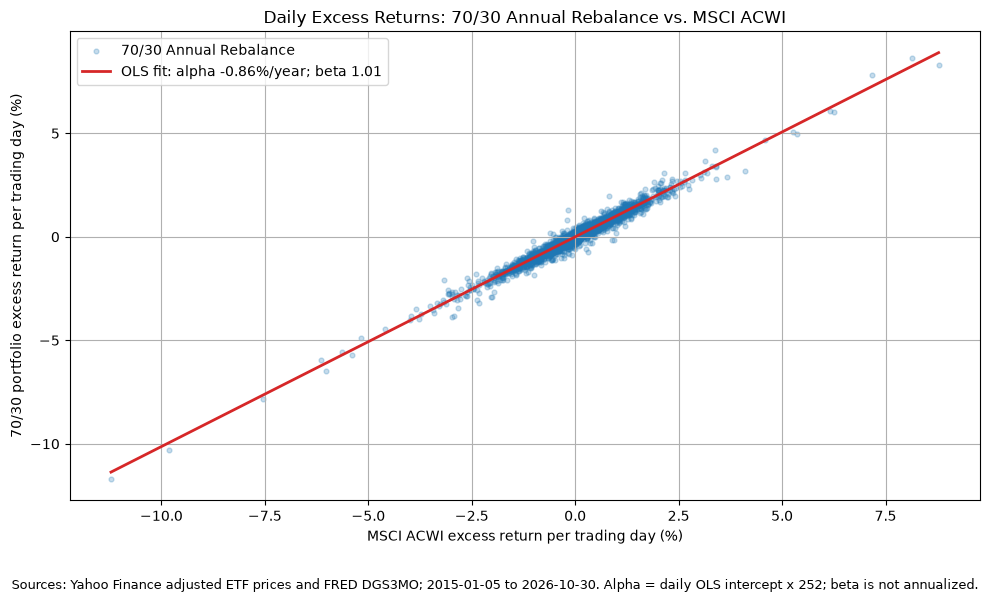

In [17]:
# %%
# The fitted line shows daily alpha in percent at x=0 and beta as its slope.
annualized_alpha, beta, strategy_excess_returns, benchmark_excess_returns = (
    market_model_metrics(
        strategy_returns,
        benchmark_returns,
        daily_risk_free_returns,
    )
)
fig, ax = plt.subplots()
ax.scatter(
    benchmark_excess_returns * 100,
    strategy_excess_returns * 100,
    alpha=0.25,
    s=12,
    label="70/30 Annual Rebalance",
)
x_line = np.linspace(
    benchmark_excess_returns.min(),
    benchmark_excess_returns.max(),
    100,
)
ax.plot(
    x_line * 100,
    (annualized_alpha / TRADING_DAYS_PER_YEAR + beta * x_line) * 100,
    color="tab:red",
    linewidth=2,
    label=f"OLS fit: alpha {annualized_alpha:.2%}/year; beta {beta:.2f}",
)
ax.set_title("Daily Excess Returns: 70/30 Annual Rebalance vs. MSCI ACWI")
ax.set_xlabel("MSCI ACWI excess return per trading day (%)")
ax.set_ylabel("70/30 portfolio excess return per trading day (%)")
ax.legend()
fig.text(
    0.5,
    0.01,
    (
        "Sources: Yahoo Finance adjusted ETF prices and FRED DGS3MO; "
        f"{strategy_excess_returns.index.min().date()} to "
        f"{strategy_excess_returns.index.max().date()}. "
        "Alpha = daily OLS intercept x 252; beta is not annualized."
    ),
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()


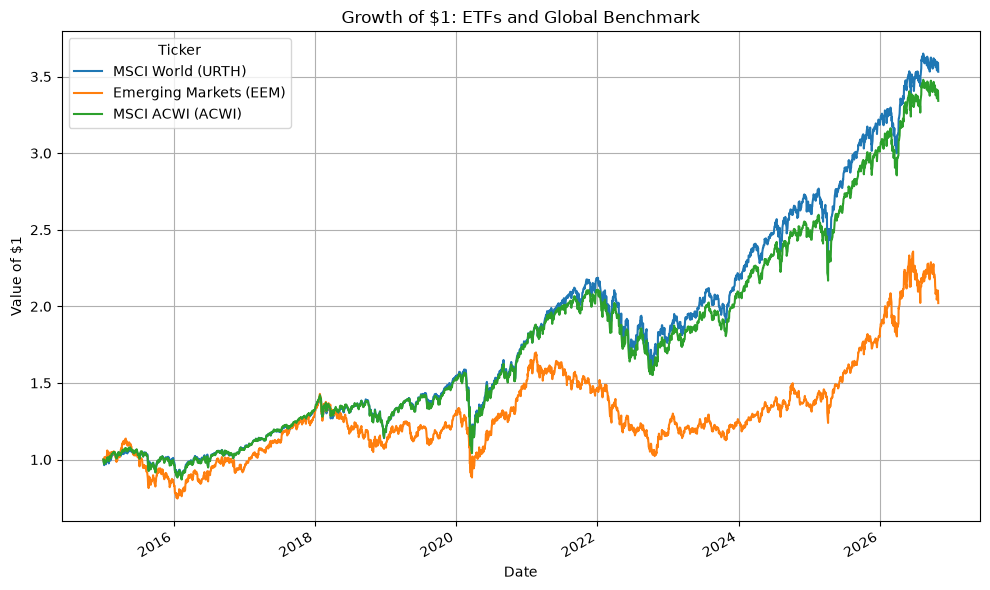

In [7]:
# Cumulative growth of $1 in each ETF and the broad-market benchmark.
growth_of_one = prices.div(prices.iloc[0])
growth_of_one.rename(
    columns={
        WORLD_TICKER: "MSCI World (URTH)",
        EM_TICKER: "Emerging Markets (EEM)",
        BENCHMARK_TICKER: "MSCI ACWI (ACWI)",
    }
).plot()
plt.title("Growth of $1: ETFs and Global Benchmark")
plt.ylabel("Value of $1")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



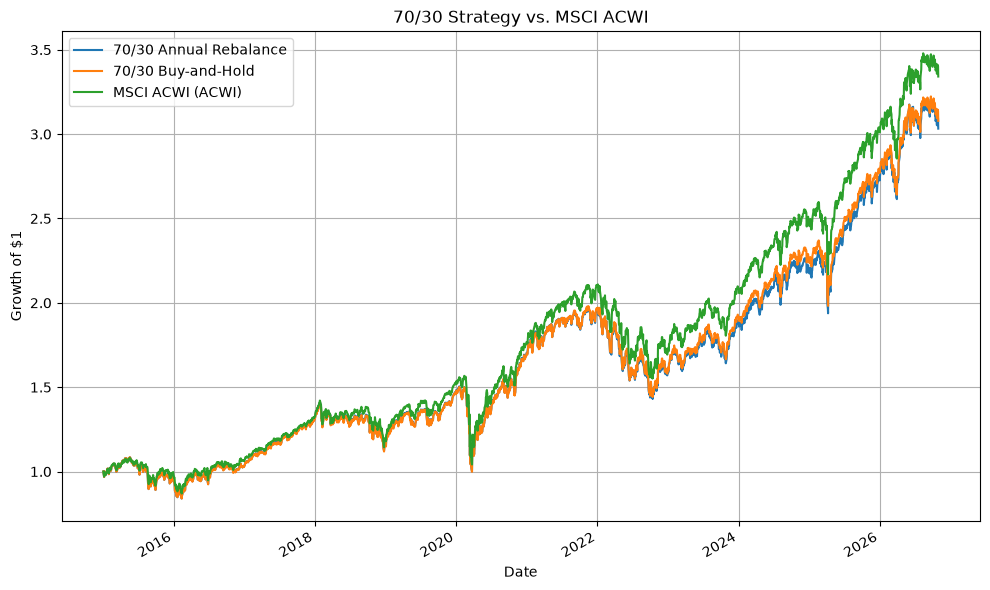

In [8]:
equity_curves.plot()
plt.title("70/30 Strategy vs. MSCI ACWI")
plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



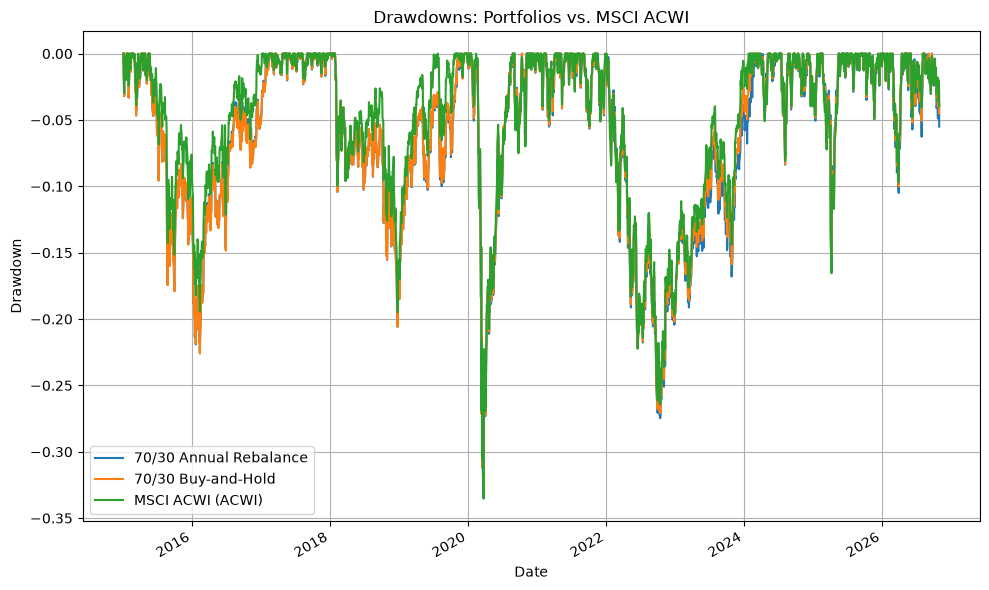

In [9]:
drawdowns = equity_curves.div(equity_curves.cummax()) - 1
drawdowns.plot()
plt.title("Drawdowns: Portfolios vs. MSCI ACWI")
plt.ylabel("Drawdown")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



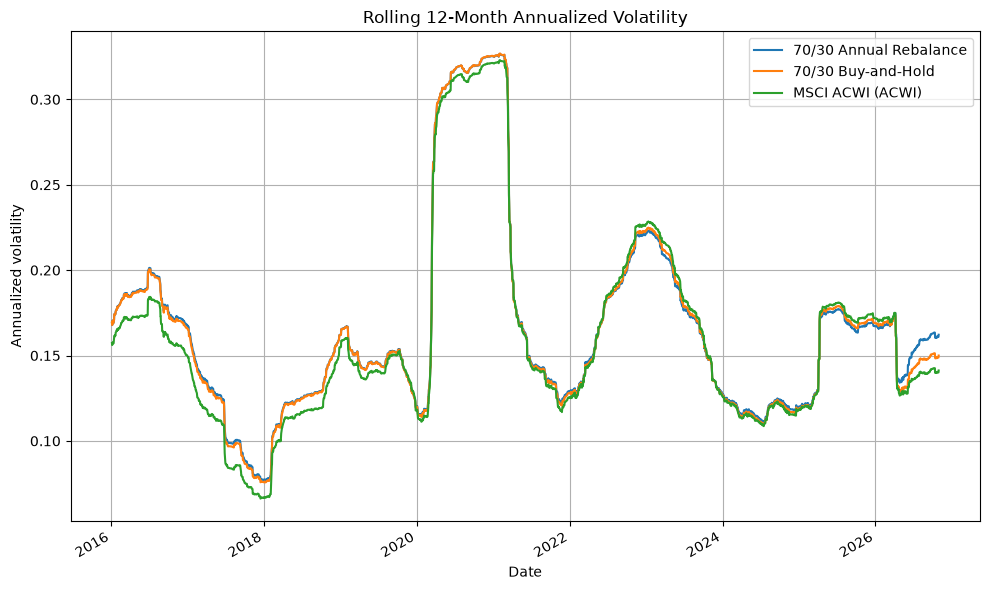

In [10]:
comparison_returns = pd.concat(
    {
        "70/30 Annual Rebalance": strategy_returns,
        "70/30 Buy-and-Hold": buy_and_hold_returns,
        "MSCI ACWI (ACWI)": benchmark_returns,
    },
    axis="columns",
    sort=False,
).dropna()
rolling_volatility = (
    comparison_returns.rolling(ROLLING_WINDOW).std() * np.sqrt(TRADING_DAYS_PER_YEAR)
)
rolling_volatility.plot()
plt.title("Rolling 12-Month Annualized Volatility")
plt.ylabel("Annualized volatility")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



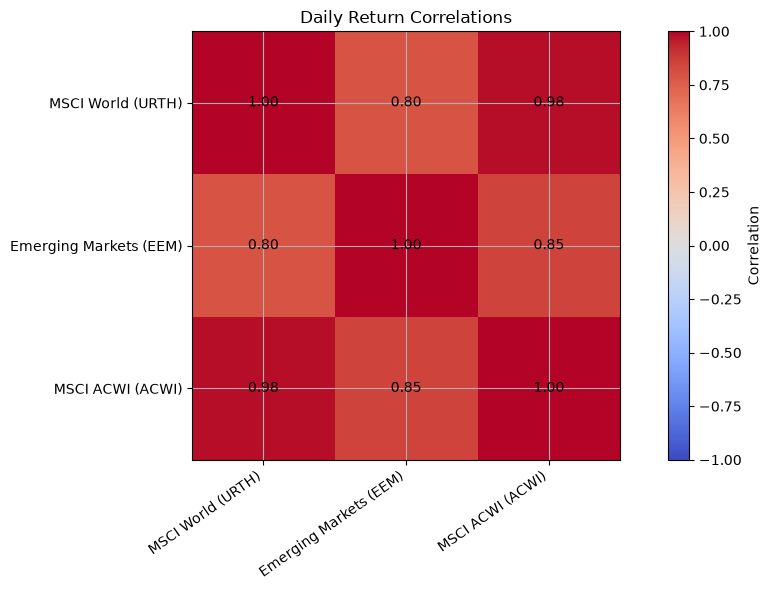

In [11]:
asset_and_benchmark_returns = pd.concat(
    [asset_returns, benchmark_returns.rename(BENCHMARK_TICKER)],
    axis="columns",
    sort=False,
).rename(
    columns={
        WORLD_TICKER: "MSCI World (URTH)",
        EM_TICKER: "Emerging Markets (EEM)",
        BENCHMARK_TICKER: "MSCI ACWI (ACWI)",
    }
)
correlations = asset_and_benchmark_returns.corr()

fig, ax = plt.subplots()
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(
    range(len(correlations.columns)),
    labels=correlations.columns,
    rotation=35,
    ha="right",
)
ax.set_yticks(range(len(correlations.index)), labels=correlations.index)
for row in range(len(correlations.index)):
    for column in range(len(correlations.columns)):
        ax.text(
            column,
            row,
            f"{correlations.iloc[row, column]:.2f}",
            ha="center",
            va="center",
        )
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Daily Return Correlations")
fig.tight_layout()
plt.show()



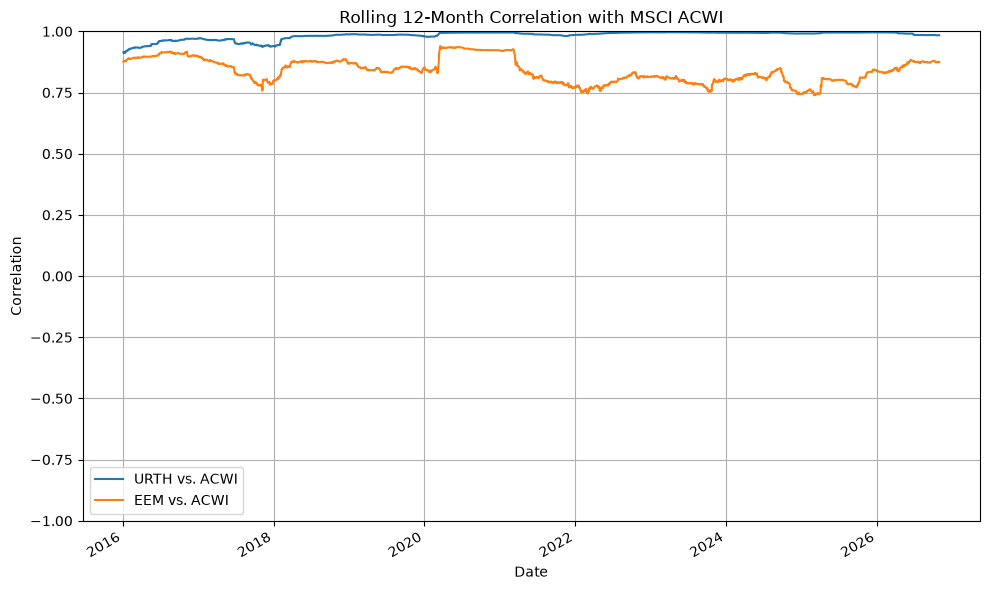

In [12]:
rolling_correlations = pd.DataFrame(
    {
        "URTH vs. ACWI": asset_returns[WORLD_TICKER].rolling(ROLLING_WINDOW).corr(
            benchmark_returns
        ),
        "EEM vs. ACWI": asset_returns[EM_TICKER].rolling(ROLLING_WINDOW).corr(
            benchmark_returns
        ),
    }
)
rolling_correlations.plot()
plt.title("Rolling 12-Month Correlation with MSCI ACWI")
plt.ylabel("Correlation")
plt.xlabel("Date")
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()



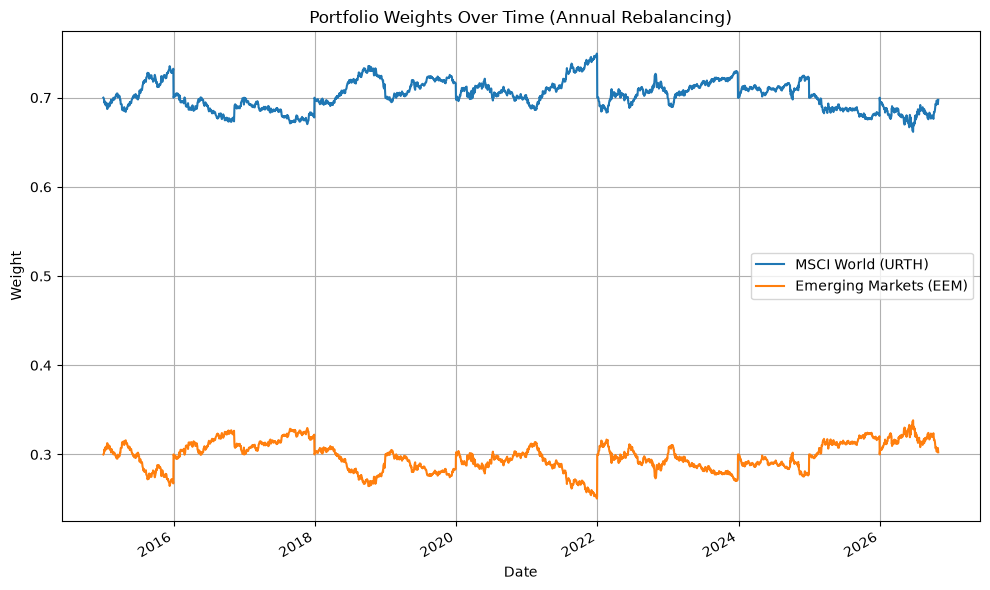

In [13]:
strategy_weights.rename(
    columns={
        WORLD_TICKER: "MSCI World (URTH)",
        EM_TICKER: "Emerging Markets (EEM)",
    }
).plot()
plt.title("Portfolio Weights Over Time (Annual Rebalancing)")
plt.ylabel("Weight")
plt.xlabel("Date")
plt.tight_layout()
plt.show()



In [14]:
# Calendar-year returns make annual performance comparisons easy to report.
calendar_year_returns = comparison_returns.groupby(comparison_returns.index.year).apply(
    lambda year_returns: (1 + year_returns).prod() - 1
)
last_data_year = prices.index[-1].year
if prices.index[-1].month < 12:
    calendar_year_returns.index = [
        f"{year}*" if year == last_data_year else str(year)
        for year in calendar_year_returns.index
    ]
else:
    calendar_year_returns.index = calendar_year_returns.index.astype(str)
calendar_year_returns.index.name = "Year"
print("Calendar-year returns:")
print(calendar_year_returns.to_string(float_format=lambda value: f"{value:.2%}"))
if prices.index[-1].month < 12:
    print(f"* Partial year through {prices.index[-1].date()}.")


Calendar-year returns:
       70/30 Annual Rebalance  70/30 Buy-and-Hold  MSCI ACWI (ACWI)
Year                                                               
2015                   -4.95%              -4.95%            -1.97%
2016                    8.37%               8.26%             8.40%
2017                   27.24%              26.88%            24.33%
2018                  -10.59%             -10.57%            -9.12%
2019                   25.17%              25.35%            26.59%
2020                   16.16%              16.11%            16.34%
2021                   14.50%              15.35%            18.66%
2022                  -18.75%             -18.55%           -18.39%
2023                   19.45%              20.68%            22.27%
2024                   15.01%              16.27%            17.45%
2025                   25.15%              23.63%            22.41%
2026*                  11.27%              11.14%            11.00%
* Partial year through 20

## Regional context: GDP and market capitalization

This section retrieves nominal GDP and GDP at PPP from the IMF DataMapper API and 2025 listed-company market capitalization from the World Bank API. It uses a fixed 47-country roster (23 MSCI World and 24 MSCI Emerging Markets countries) taken from the November 25, 2026 iShares holdings snapshot; it does not read local files. The country roster is held constant for the 2015–2025 GDP trend. Recent GDP observations may be estimates. The 70/30 target is a comparison line, not a weight calculated from GDP or market capitalization.



In [ ]:
import json
from urllib.request import urlopen

DEVELOPED_COUNTRIES = {
    "Australia": "AUS", "Austria": "AUT", "Belgium": "BEL", "Canada": "CAN",
    "Denmark": "DNK", "Finland": "FIN", "France": "FRA", "Germany": "DEU",
    "Hong Kong": "HKG", "Ireland": "IRL", "Israel": "ISR", "Italy": "ITA",
    "Japan": "JPN", "Netherlands": "NLD", "New Zealand": "NZL", "Norway": "NOR",
    "Portugal": "PRT", "Singapore": "SGP", "Spain": "ESP", "Sweden": "SWE",
    "Switzerland": "CHE", "United Kingdom": "GBR", "United States": "USA",
}
EMERGING_COUNTRIES = {
    "Brazil": "BRA", "Chile": "CHL", "China": "CHN", "Colombia": "COL",
    "Czech Republic": "CZE", "Egypt": "EGY", "Greece": "GRC", "Hungary": "HUN",
    "India": "IND", "Indonesia": "IDN", "Korea (South)": "KOR", "Kuwait": "KWT",
    "Malaysia": "MYS", "Mexico": "MEX", "Peru": "PER", "Philippines": "PHL",
    "Poland": "POL", "Qatar": "QAT", "Saudi Arabia": "SAU", "South Africa": "ZAF",
    "Taiwan": "TWN", "Thailand": "THA", "Turkey": "TUR", "United Arab Emirates": "ARE",
}
REGIONAL_YEARS = range(2015, 2026)
COMPARISON_YEAR = 2025
em_target_pct = TARGET_WEIGHTS[EM_TICKER] * 100


def fetch_json(url: str) -> object:
    with urlopen(url, timeout=30) as response:
        return json.load(response)


def fetch_imf_indicator(indicator: str) -> dict:
    payload = fetch_json(f"https://www.imf.org/external/datamapper/api/v1/{indicator}")
    values = payload.get("values", {}).get(indicator)
    if not isinstance(values, dict):
        raise ValueError(f"IMF DataMapper response does not contain {indicator} data.")
    countries = {**DEVELOPED_COUNTRIES, **EMERGING_COUNTRIES}
    missing = [
        country
        for country, code in countries.items()
        if any(values.get(code, {}).get(str(year)) is None for year in REGIONAL_YEARS)
    ]
    if missing:
        raise ValueError(f"IMF {indicator} data is missing 2015–2025 values for: {', '.join(missing)}")
    return values


def imf_em_share(values: dict, year: int) -> float:
    developed_total = sum(values[code][str(year)] for code in DEVELOPED_COUNTRIES.values())
    emerging_total = sum(values[code][str(year)] for code in EMERGING_COUNTRIES.values())
    combined_total = developed_total + emerging_total
    if combined_total <= 0:
        raise ValueError(f"IMF {year} GDP total must be positive.")
    return emerging_total / combined_total * 100


nominal_gdp = fetch_imf_indicator("NGDPD")
ppp_gdp = fetch_imf_indicator("PPPGDP")
nominal_em_share = imf_em_share(nominal_gdp, COMPARISON_YEAR)
ppp_em_share = imf_em_share(ppp_gdp, COMPARISON_YEAR)

gdp_trend_rows = []
for indicator_name, values in (
    ("Nominal GDP (current US$)", nominal_gdp),
    ("GDP at PPP (international $)", ppp_gdp),
):
    for year in REGIONAL_YEARS:
        gdp_trend_rows.append(
            {
                "Year": year,
                "GDP basis": indicator_name,
                "Emerging-market share (%)": imf_em_share(values, year),
            }
        )
gdp_share_trend = pd.DataFrame(gdp_trend_rows)

world_bank_url = (
    "https://api.worldbank.org/v2/country/all/indicator/CM.MKT.LCAP.CD"
    f"?date={COMPARISON_YEAR}&format=json&per_page=1000"
)
world_bank_payload = fetch_json(world_bank_url)
if not isinstance(world_bank_payload, list) or len(world_bank_payload) < 2 or not world_bank_payload[1]:
    raise ValueError("World Bank API did not return country market-cap observations.")
world_bank_update = world_bank_payload[0].get("lastupdated", "date not provided")
market_cap_by_country = {
    row["countryiso3code"]: float(row["value"])
    for row in world_bank_payload[1]
    if row.get("countryiso3code") and row.get("value") is not None
}

developed_market_caps = [
    market_cap_by_country[code]
    for code in DEVELOPED_COUNTRIES.values()
    if code in market_cap_by_country
]
emerging_market_caps = [
    market_cap_by_country[code]
    for code in EMERGING_COUNTRIES.values()
    if code in market_cap_by_country
]
if not developed_market_caps or not emerging_market_caps:
    raise ValueError("World Bank market-cap data must cover both country groups.")
market_cap_total = sum(developed_market_caps) + sum(emerging_market_caps)
market_cap_em_share = sum(emerging_market_caps) / market_cap_total * 100
market_cap_coverage = (
    f"Developed {len(developed_market_caps)}/{len(DEVELOPED_COUNTRIES)}; "
    f"Emerging {len(emerging_market_caps)}/{len(EMERGING_COUNTRIES)}"
)

regional_summary = pd.DataFrame(
    [
        {"Comparison": "IMF nominal GDP, 2025", "EM share (%)": nominal_em_share, "Coverage": "47/47 countries"},
        {"Comparison": "IMF GDP at PPP, 2025", "EM share (%)": ppp_em_share, "Coverage": "47/47 countries"},
        {"Comparison": "World Bank/WFE market cap, 2025", "EM share (%)": market_cap_em_share, "Coverage": market_cap_coverage},
    ]
)
print(f"Regional comparison; World Bank API updated {world_bank_update}:")
print(
    regional_summary.to_string(
        index=False,
        formatters={"EM share (%)": lambda value: f"{value:.1f}%"},
    )
)

fig, ax = plt.subplots(figsize=(10, 5.5))
for basis, label in (
    ("Nominal GDP (current US$)", "Nominal GDP (current US$)"),
    ("GDP at PPP (international $)", "GDP at PPP (international $)"),
):
    series = gdp_share_trend.loc[gdp_share_trend["GDP basis"].eq(basis)].sort_values("Year")
    ax.plot(series["Year"], series["Emerging-market share (%)"], marker="o", linewidth=2, label=label)
ax.axhline(em_target_pct, color="#454545", linestyle="--", linewidth=1.2, label=f"Portfolio target: {em_target_pct:g}% EM")
ax.set_title("Emerging markets' share of GDP over time")
ax.set_xlabel("Year")
ax.set_ylabel("Emerging-market share of combined GDP (%)")
ax.set_xticks(list(REGIONAL_YEARS))
ax.set_ylim(25, 65)
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
fig.text(
    0.01,
    0.01,
    "Source: IMF DataMapper API (NGDPD and PPPGDP), 2015–2025.\n"
    "Fixed 47-country roster from November 25, 2026 holdings. Recent GDP values may be estimates.",
    fontsize=8,
)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


## Benchmark comparison by region, country, and sector

ACWI covers developed and emerging markets. URTH tracks MSCI World, which covers developed markets. The iShares API supplies holdings for URTH, EEM, and ACWI on November 25, 2026. We sum equity positions by country of risk and sector, then combine URTH and EEM using the 70/30 target. Exposures are percentages of total NAV. The regional allocation table shows the intended 70/30 fund weights alongside the ETFs’ measured equity exposures.

The two panels distinguish portfolio allocation from economic context. IMF GDP measures production, including purchasing-power differences in the PPP series. World Bank/WFE capitalization covers listed domestic companies in the countries with available data. The holdings comparison is a single snapshot after the backtest period.


In [ ]:
from urllib.parse import urlencode
from urllib.request import Request

HOLDINGS_DATE = "2026-11-25"
ISHARES_PORTFOLIO_IDS = {
    WORLD_TICKER: 239696,
    EM_TICKER: 239637,
    BENCHMARK_TICKER: 239600,
}
ISHARES_HOLDINGS_API = (
    "https://www.ishares.com/varnish-api/blk-one01-product-data/"
    "product-data/api/v2/get-product-data"
)


def fetch_etf_holdings(ticker: str) -> pd.DataFrame:
    requested_date = int(HOLDINGS_DATE.replace("-", ""))
    query = urlencode(
        {
            "appSubType": "ISHARES",
            "appType": "PRODUCT_PAGE",
            "component": "holdings.all",
            "locale": "en_US",
            "portfolioId": ISHARES_PORTFOLIO_IDS[ticker],
            "targetSite": "us-ishares",
            "userType": "individual",
            "excludeContent": "true",
            "asOfDate": requested_date,
            "includeConfig": "true",
        }
    )
    request = Request(
        f"{ISHARES_HOLDINGS_API}?{query}",
        headers={"Accept": "application/json", "x-application-id": "pp-ui-csr"},
    )
    with urlopen(request, timeout=30) as response:
        payload = json.load(response)

    try:
        holdings = payload["componentsByNameMap"]["holdings"]
        fields = holdings["containersByNameMap"]["all"]["dataPointsByNameMap"]
        actual_date = fields["asOfDate"]["value"]
        positions = pd.DataFrame(
            {
                "Country": fields["countryOfRisk"]["value"],
                "Sector": fields["sectorName"]["value"],
                "Asset class": fields["assetClass"]["value"],
                "Weight (%)": fields["holdingPercent"]["value"],
            }
        )
    except (KeyError, TypeError, ValueError) as error:
        raise ValueError(f"iShares returned an invalid holdings table for {ticker}.") from error

    if str(actual_date) != str(requested_date):
        raise ValueError(f"Expected {ticker} holdings for {HOLDINGS_DATE}, received {actual_date}.")

    positions["Weight (%)"] = pd.to_numeric(positions["Weight (%)"], errors="raise")
    if not np.isclose(positions["Weight (%)"].sum(), 100, atol=0.1):
        raise ValueError(f"iShares weights for {ticker} must sum to approximately 100%.")
    return positions.loc[positions["Asset class"].eq("Equity")]

portfolio_column = "70/30 portfolio"
benchmark_column = "MSCI ACWI (ACWI)"
world_column = "MSCI World (URTH)"
fund_columns = dict(zip(ALL_TICKERS, [world_column, EM_TICKER, benchmark_column]))
comparison_columns = [portfolio_column, benchmark_column, world_column]
comparison_colors = ["#1D5673", "#B56A2B", "#7A858B"]


def equity_exposure(group: str, equity_holdings: dict[str, pd.DataFrame]) -> pd.DataFrame:
    weights_by_fund = {}
    for ticker, equities in equity_holdings.items():
        labeled_equities = equities.loc[~equities[group].isin(["", "--"])]
        weights_by_fund[ticker] = labeled_equities.groupby(group)["Weight (%)"].sum()

    exposure = pd.DataFrame(weights_by_fund).fillna(0)
    exposure[portfolio_column] = exposure[TARGET_WEIGHTS.index].dot(TARGET_WEIGHTS)
    return exposure.rename(columns=fund_columns).sort_values(portfolio_column, ascending=False)


equity_holdings = {ticker: fetch_etf_holdings(ticker) for ticker in ALL_TICKERS}
country_exposure = equity_exposure("Country", equity_holdings)
sector_exposure = equity_exposure("Sector", equity_holdings)

fund_regions = pd.DataFrame(
    {
        "Developed-market equities": country_exposure.reindex(DEVELOPED_COUNTRIES).sum(),
        "Emerging-market equities": country_exposure.reindex(EMERGING_COUNTRIES).sum(),
    }
).loc[[benchmark_column, world_column]]
fund_regions["Other exposure"] = 100 - fund_regions.sum(axis=1)
fund_regions = pd.concat(
    [
        pd.DataFrame(
            [[100 - em_target_pct, em_target_pct, 0]],
            index=[f"{portfolio_column} target"],
            columns=fund_regions.columns,
        ),
        fund_regions,
    ]
)
print(f"Target allocation and ETF holdings (%), {HOLDINGS_DATE}")
print(fund_regions.round(2).to_string())
print("\nCountry equity exposure (% of NAV)")
print(country_exposure[comparison_columns].round(2).to_string())
print("\nSector equity exposure (% of NAV)")
print(sector_exposure[comparison_columns].round(2).to_string())

capital_allocation = fund_regions["Emerging-market equities"]
economic_context = regional_summary.set_index("Comparison")["EM share (%)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharex=True, layout="constrained")
for ax, title, shares, colors in (
    (axes[0], "Portfolio target and ETF holdings", capital_allocation, comparison_colors),
    (axes[1], f"Economic and market data ({COMPARISON_YEAR})", economic_context,
     ["#438176", "#438176", "#8F7150"]),
):
    bars = ax.barh(shares.index, shares, color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=4)
    ax.invert_yaxis()
    ax.set_xlim(0, max(65, economic_context.max() + 8))
    ax.set_xlabel("Emerging-market share (%)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
fig.suptitle("Emerging-market weights in portfolios and in the economy")
fig.supxlabel(
    f"iShares ETF holdings: {HOLDINGS_DATE}. IMF GDP covers the fixed 47-country roster.\n"
    f"World Bank/WFE listed-company market-cap coverage: {market_cap_coverage}.",
    fontsize=9,
)
plt.show()

# Rank by the largest weight across the three portfolios so the chart also
# includes countries with large benchmark weights. The full table is above.
country_comparison = country_exposure[comparison_columns]
top_countries = country_comparison.max(axis=1).nlargest(10).index
for title, weights in (
    ("Largest country equity exposures", country_comparison.loc[top_countries]),
    ("Equity sector exposures", sector_exposure[comparison_columns]),
):
    ax = weights.iloc[::-1].plot.barh(
        figsize=(10, 7.5), width=0.78, color=comparison_colors, zorder=2
    )
    for bars in ax.containers:
        labels = [f"{bar.get_width():.1f}%" if bar.get_width() >= 0.05 else "" for bar in bars]
        ax.bar_label(bars, labels=labels, padding=3, fontsize=7)
    ax.set_xlim(0, weights.max().max() * 1.19)
    ax.set_xlabel("Share of total portfolio or fund NAV (%)")
    ax.set_ylabel("")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    fig = ax.get_figure()
    fig.text(0.02, 0.02, f"Source: iShares holdings API ({HOLDINGS_DATE}). Equity positions only.", fontsize=8)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()
